### Imports

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split, learning_curve
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
from sentence_transformers import SentenceTransformer

SEED = 777

### Load and Split Data

In [90]:
data = pd.read_csv("household_item_descriptions.csv")

X = data["description"]
y = data["item"]

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.4, random_state=SEED, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=SEED, stratify=y_temp)

print("Training num:", len(X_train))
print("Validation num:", len(X_val))
print("Testing num:", len(X_test))

Training num: 120
Validation num: 40
Testing num: 40


# TF-IDF


In [91]:
vectorizer = TfidfVectorizer(lowercase=True, 
                             stop_words="english", 
                             ngram_range=(1, 2)) # Adjust the range to see what works best

# Learn vocabulary and calculate TF-IDF values
X_train_tfidf = vectorizer.fit_transform(X_train)

# Transform validation/testing descriptions using the same vocabulary
X_val_tfidf = vectorizer.transform(X_val)
X_test_tfidf = vectorizer.transform(X_test)

print("Training matrix shape:", X_train_tfidf.shape)
print("Validation matrix shape:", X_val_tfidf.shape)
print("Testing matrix shape:", X_test_tfidf.shape)

Training matrix shape: (120, 988)
Validation matrix shape: (40, 988)
Testing matrix shape: (40, 988)


In [92]:
tfidf_model = LogisticRegression(max_iter=2000, C=10)

tfidf_model.fit(X_train_tfidf, y_train)

,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",10
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",2000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in

In [93]:
# Generate predictions
tfidf_training_predictions = tfidf_model.predict(X_train_tfidf)
tfidf_val_predictions = tfidf_model.predict(X_val_tfidf)
tfidf_test_predictions = tfidf_model.predict(X_test_tfidf)

# Calculate accuracy
tfidf_training_accuracy = accuracy_score(y_train, tfidf_training_predictions)
tfidf_val_accuracy = accuracy_score(y_val, tfidf_val_predictions)
tfidf_test_accuracy = accuracy_score(y_test, tfidf_test_predictions)

print("Training Accuracy:", tfidf_training_accuracy)
print("Validation Accuracy:", tfidf_val_accuracy)
print("Testing Accuracy:", tfidf_test_accuracy)

print("\nTesting Report:")
print(classification_report(y_test, tfidf_test_predictions, zero_division=0))

Training Accuracy: 1.0
Validation Accuracy: 0.2
Testing Accuracy: 0.3

Testing Report:
                precision    recall  f1-score   support

       blanket       0.00      0.00      0.00         1
          book       1.00      1.00      1.00         1
         broom       0.00      0.00      0.00         1
         chair       0.50      1.00      0.67         1
         clock       1.00      1.00      1.00         1
clothes hanger       0.00      0.00      0.00         1
 cutting board       0.50      1.00      0.67         1
       dustpan       0.00      0.00      0.00         1
extension cord       1.00      1.00      1.00         1
    flashlight       0.00      0.00      0.00         1
          fork       0.00      0.00      0.00         1
    frying pan       0.00      0.00      0.00         1
        kettle       0.25      1.00      0.40         1
          lamp       0.00      0.00      0.00         1
laundry basket       1.00      1.00      1.00         1
     microwave  

c:\Users\ablue\Documents\Coding Projects\4210 Repos\House Predictor Model\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1447: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  check_classification_targets(y)
c:\Users\ablue\Documents\Coding Projects\4210 Repos\House Predictor Model\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1447: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  check_classification_targets(y)
c:\Users\ablue\Documents\Coding Projects\4210 Repos\House Predictor Model\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1447: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  check_classification_targets(y)
c:\U

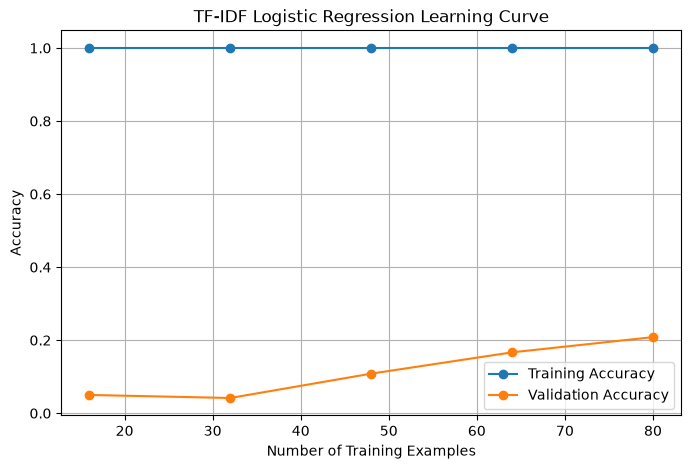

In [94]:
# Generate learning curve
train_sizes, train_scores, val_scores = learning_curve(
    tfidf_model,
    X_train_tfidf,
    y_train,
    cv=3,
    scoring="accuracy",
    train_sizes=[0.2, 0.4, 0.6, 0.8, 1.0]
)

# Calculate average accuracy for each training size
train_mean = train_scores.mean(axis=1)
val_mean = val_scores.mean(axis=1)

# Plot learning curve
plt.figure(figsize=(8, 5))

plt.plot(train_sizes, train_mean, marker="o", label="Training Accuracy")
plt.plot(train_sizes, val_mean, marker="o", label="Validation Accuracy")

plt.xlabel("Number of Training Examples")
plt.ylabel("Accuracy")
plt.title("TF-IDF Logistic Regression Learning Curve")

plt.legend()
plt.grid()
plt.show()

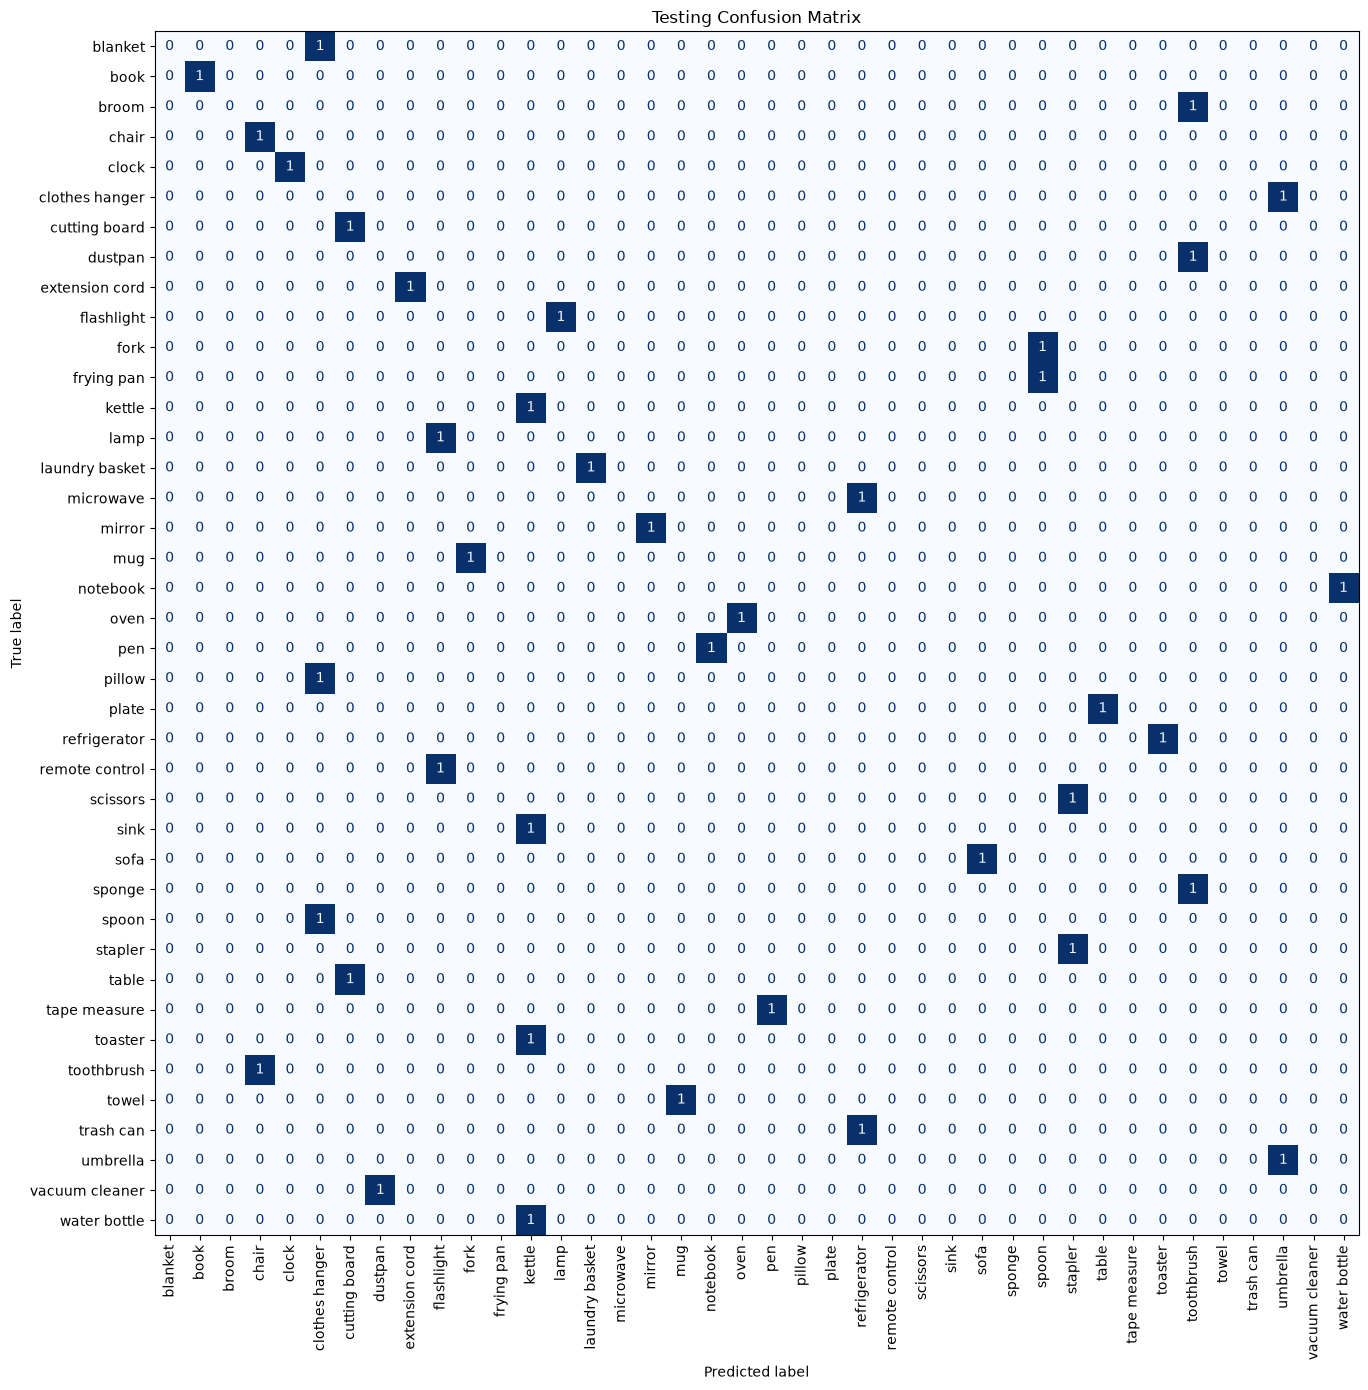

In [95]:
# Generate confusion matrix using testing predictions
cm = confusion_matrix(y_test, tfidf_test_predictions, labels=tfidf_model.classes_)

# Display confusion matrix
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=tfidf_model.classes_
)

fig, ax = plt.subplots(figsize=(14, 14))

display.plot(
    ax=ax,
    xticks_rotation=90,
    cmap="Blues",
    colorbar=False
)

plt.title("Testing Confusion Matrix")
plt.tight_layout()
plt.show()

# Sentence Embeddings

In [96]:
encoder = SentenceTransformer("all-MiniLM-L6-v2")
 
# encode() wants a list of strings, and your X_* variables are pandas Series
X_train_embed = encoder.encode(X_train.tolist(), normalize_embeddings=True, show_progress_bar=True)
X_val_embed = encoder.encode(X_val.tolist(), normalize_embeddings=True)
X_test_embed = encoder.encode(X_test.tolist(), normalize_embeddings=True)
 
print("Training embeddings shape:", X_train_embed.shape)    # (120, 384) with your current data
print("Validation embeddings shape:", X_val_embed.shape)
print("Testing embeddings shape:", X_test_embed.shape)

Batches: 100%|██████████| 4/4 [00:00<00:00, 33.77it/s]


Training embeddings shape: (120, 384)
Validation embeddings shape: (40, 384)
Testing embeddings shape: (40, 384)


In [97]:
# Same classifier and C as the TF-IDF model, so any difference in results
# comes from how the text is represented, not from the classifier.
embed_model = LogisticRegression(max_iter=2000, C=10)
embed_model.fit(X_train_embed, y_train)

,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",10
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",2000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in

In [98]:
embed_train_pred = embed_model.predict(X_train_embed)
embed_val_pred = embed_model.predict(X_val_embed)
embed_test_pred = embed_model.predict(X_test_embed)
 
embed_train_acc = accuracy_score(y_train, embed_train_pred)
embed_val_acc = accuracy_score(y_val, embed_val_pred)
embed_test_acc = accuracy_score(y_test, embed_test_pred)
 
print("Training Accuracy:", embed_train_acc)
print("Validation Accuracy:", embed_val_acc)
print("Testing Accuracy:", embed_test_acc)
 
print("\nTesting Report:")
print(classification_report(y_test, embed_test_pred, zero_division=0))

Training Accuracy: 1.0
Validation Accuracy: 0.6
Testing Accuracy: 0.55

Testing Report:
                precision    recall  f1-score   support

       blanket       0.00      0.00      0.00         1
          book       0.50      1.00      0.67         1
         broom       0.00      0.00      0.00         1
         chair       1.00      1.00      1.00         1
         clock       1.00      1.00      1.00         1
clothes hanger       0.00      0.00      0.00         1
 cutting board       0.00      0.00      0.00         1
       dustpan       0.00      0.00      0.00         1
extension cord       0.50      1.00      0.67         1
    flashlight       0.50      1.00      0.67         1
          fork       0.00      0.00      0.00         1
    frying pan       1.00      1.00      1.00         1
        kettle       1.00      1.00      1.00         1
          lamp       0.00      0.00      0.00         1
laundry basket       0.50      1.00      0.67         1
     microwave 

c:\Users\ablue\Documents\Coding Projects\4210 Repos\House Predictor Model\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1447: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  check_classification_targets(y)
c:\Users\ablue\Documents\Coding Projects\4210 Repos\House Predictor Model\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1447: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  check_classification_targets(y)
c:\Users\ablue\Documents\Coding Projects\4210 Repos\House Predictor Model\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1447: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  check_classification_targets(y)
c:\U

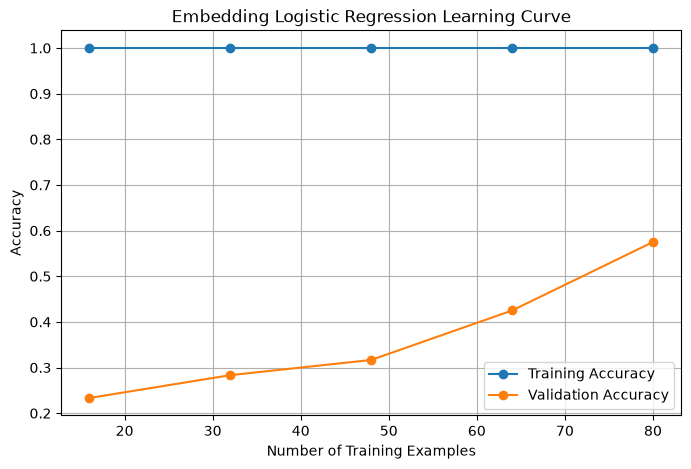

In [99]:
# Generate learning curve
train_sizes, train_scores, val_scores = learning_curve(
    embed_model,
    X_train_embed,
    y_train,
    cv=3,
    scoring="accuracy",
    train_sizes=[0.2, 0.4, 0.6, 0.8, 1.0]
)

# Calculate average accuracy for each training size
train_mean = train_scores.mean(axis=1)
val_mean = val_scores.mean(axis=1)

# Plot learning curve
plt.figure(figsize=(8, 5))

plt.plot(train_sizes, train_mean, marker="o", label="Training Accuracy")
plt.plot(train_sizes, val_mean, marker="o", label="Validation Accuracy")

plt.xlabel("Number of Training Examples")
plt.ylabel("Accuracy")
plt.title("Embedding Logistic Regression Learning Curve")

plt.legend()
plt.grid()
plt.show()

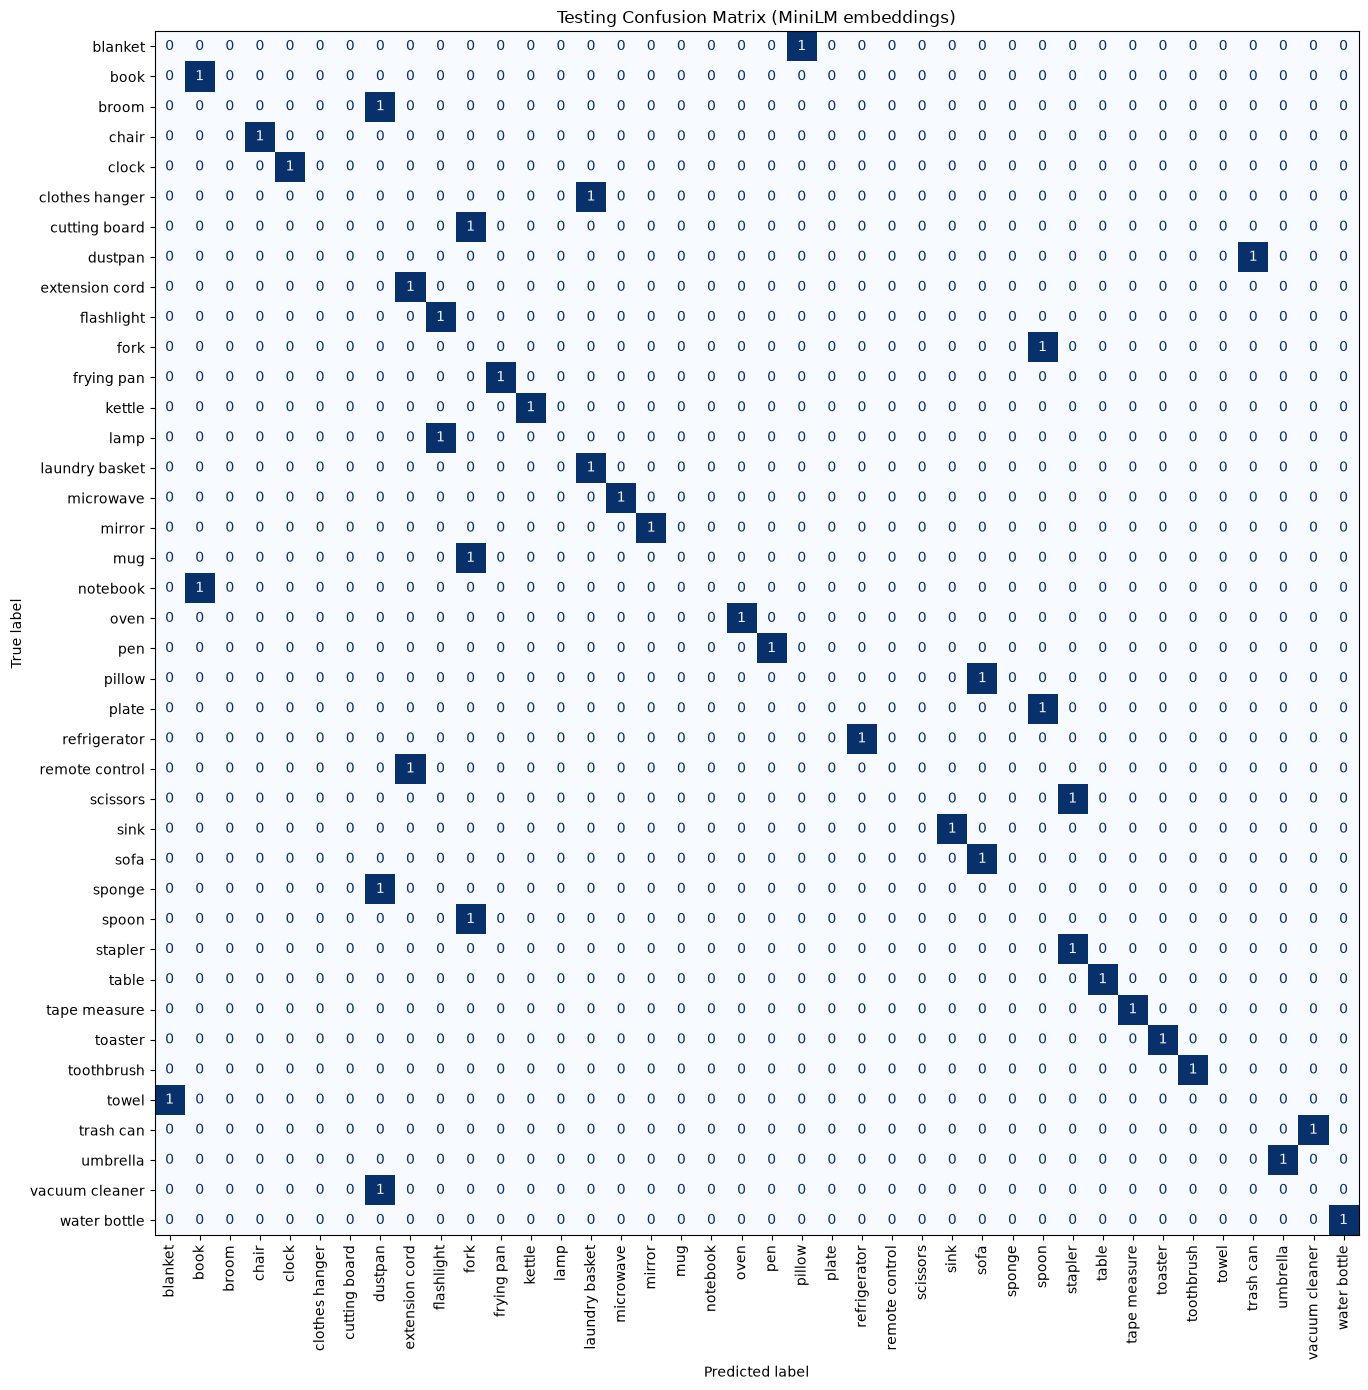

In [100]:
cm = confusion_matrix(y_test, embed_test_pred, labels=embed_model.classes_)
display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=embed_model.classes_)
 
fig, ax = plt.subplots(figsize=(14, 14))
display.plot(ax=ax, xticks_rotation=90, cmap="Blues", colorbar=False)
plt.title("Testing Confusion Matrix (MiniLM embeddings)")
plt.tight_layout()
plt.show()

In [101]:
# (uses val_accuracy and test_accuracy from your TF-IDF cell)
print(f"{'Method':<28}{'Validation':>12}{'Test':>10}")
print(f"{'TF-IDF + LogReg':<28}{tfidf_val_accuracy:>12.3f}{tfidf_test_accuracy:>10.3f}")
print(f"{'MiniLM embeddings + LogReg':<28}{embed_val_acc:>12.3f}{embed_test_acc:>10.3f}")

Method                        Validation      Test
TF-IDF + LogReg                    0.200     0.300
MiniLM embeddings + LogReg         0.600     0.550


In [102]:
def predict_item_tfidf(description):
    # Convert description into TF-IDF features
    description_tfidf = vectorizer.transform([description])

    # Predict household item
    prediction = tfidf_model.predict(description_tfidf)[0]

    # Get probabilities for each possible item
    probabilities = tfidf_model.predict_proba(description_tfidf)[0]

    # Get indices of the three highest probabilities
    top_indices = probabilities.argsort()[::-1][:3]


    print("TF-IDF Results:")
    print("Description:", description)
    print("Predicted item:", prediction)

    print("\nTop 3 TF-IDF predictions:")

    for index in top_indices:
        item = tfidf_model.classes_[index]
        probability = probabilities[index]

        print(f"Tf-IDF: {item}: {probability:.2%}")
        

In [103]:
def predict_item_embeddings(description):

    description_embed = encoder.encode([description], normalize_embeddings=True)
    prediction = embed_model.predict(description_embed)[0]
    probabilities = embed_model.predict_proba(description_embed)[0]
    top_indices = probabilities.argsort()[::-1][:3]

    print("Embedding Results:")
    print("Description:", description)
    print("Predicted item:", prediction)

    print("\nTop 3 Embedding predictions:")

    for index in top_indices:
        item = embed_model.classes_[index]
        probability = probabilities[index]
        print(f"Embeddings: {item}: {probability:.2%}")


In [104]:
# Describing  spoon
print("=============== Describing a spoon ===============")
predict_item_tfidf("Object with a round end used to eat soup")
print()
predict_item_embeddings("Object with a round end used to eat soup")


# Describing pen
print("\n=============== Describing a pen ===============")
predict_item_tfidf("Used to write, but can not be erased")
print()
predict_item_embeddings("Used to write, but can not be erased")

=============== Describing a spoon ===============
TF-IDF Results:
Description: Object with a round end used to eat soup
Predicted item: blanket

Top 3 TF-IDF predictions:
Tf-IDF: blanket: 5.65%
Tf-IDF: mirror: 4.48%
Tf-IDF: microwave: 4.44%

Embedding Results:
Description: Object with a round end used to eat soup
Predicted item: fork

Top 3 Embedding predictions:
Embeddings: fork: 33.76%
Embeddings: spoon: 6.58%
Embeddings: frying pan: 5.71%

=============== Describing a pen ===============
TF-IDF Results:
Description: Used to write, but can not be erased
Predicted item: notebook

Top 3 TF-IDF predictions:
Tf-IDF: notebook: 5.60%
Tf-IDF: mirror: 3.68%
Tf-IDF: blanket: 3.53%

Embedding Results:
Description: Used to write, but can not be erased
Predicted item: notebook

Top 3 Embedding predictions:
Embeddings: notebook: 17.31%
Embeddings: pen: 9.22%
Embeddings: book: 6.59%


In [106]:
user_description = input("Please write a description of a house object you are thinking of: ")
predict_item_tfidf(user_description)
print()
predict_item_embeddings(user_description)


TF-IDF Results:
Description: A thing you can write with
Predicted item: remote control

Top 3 TF-IDF predictions:
Tf-IDF: remote control: 6.05%
Tf-IDF: notebook: 5.34%
Tf-IDF: sponge: 5.32%

Embedding Results:
Description: A thing you can write with
Predicted item: notebook

Top 3 Embedding predictions:
Embeddings: notebook: 16.92%
Embeddings: book: 15.69%
Embeddings: pen: 6.88%
